# Part 2 – Extending the marketing mix model

Arla Protein UK, 156 weeks (Jan 2022 – Dec 2024). This notebook tells the story of part 2 from the baseline of part 1 to the budget recommendation and the dashboard interface. All logic lives in the package `arla_mmm` (`src/arla_mmm/`); the notebook only calls it.

**To run:** from the repo root, `pip install -r requirements.txt && pip install -e .`, then run all cells (well under a minute). Section 1 reads the model comparison written by `python scripts/run_part2.py` (5 minutes, already in the repo); everything else is computed here. The slide figures shown are the files in `results/part2/figures/`, written by `scripts/run_insights.py` and `scripts/run_interface.py`.

Slide-ready summary: `results/part2/SUMMARY.md`. Every decision with its reason: `docs/part2/LOG.md`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from arla_mmm import insights as ins
from arla_mmm.data import CHANNELS, RESULTS_DIR, load_data
from arla_mmm.final import final_model
from arla_mmm.scenarios import standard_scenarios
from arla_mmm.interface import load_model, baseline_plan, scale_plan, shift_budget, forecast, compare_scenarios, backtest

pd.set_option("display.max_columns", 30, "display.width", 200, "display.float_format", "{:,.2f}".format)
data = load_data()
print(len(data), "weeks,", data["week_beg"].min().date(), "to", data["week_beg"].max().date())
data.head(3)

156 weeks, 2022-01-03 to 2024-12-23


,week_beg,sales_units,avg_price,revenue,price_promo,tv,instagram,tiktok,influencer,pos_promotion
0,2022-01-03,835343,0.93,"776,869.00",1,"289,815.00","21,672.00","18,525.00","20,130.00","33,731.00"
1,2022-01-10,746821,1.09,"814,035.00",1,"214,368.00","23,573.00","14,835.00","19,822.00","26,029.00"
2,2022-01-17,995265,1.36,"1,353,560.00",0,"245,193.00","23,536.00","20,487.00","25,963.00","30,095.00"


## 1. From part 1's model to the final model

Part 1 (model M0) regressed log sales on last week's sales, price, the promo flag and log(spend + 1) per channel. Its own caveats were our to-do list: contributions summing to 150–160% of sales, TV reduced to an on/off effect by log(x + 1), price and promo flag collinear, no trend or seasonality, one carry-over rate for everything.

We changed one thing at a time and kept a change only if it improved the information criteria **and** the forecast on unseen weeks, passed the residual checks and made business sense. The table shows the main rungs of the ladder (all 20 candidates: `results/part2/model_comparison.md`).

In [2]:
comparison = pd.read_csv(RESULTS_DIR / "model_comparison.csv").set_index("model")
rungs = {
    "M0_baseline": "part 1",
    "M1_trend": "+ linear trend",
    "M2_season": "+ seasonality",
    "M5_january": "+ shelf price / promo depth, post-promo dip, January",
    "M8_adstock_5decays": "adstock per channel instead of lagged sales",
    "M9_adstock_lag": "adstock per channel and lagged sales",
    "M14_hill": "+ Hill curve = final model",
    "M19_all_synergies": "+ four synergy terms (rejected)",
}
ladder = comparison.loc[list(rungs), ["k", "aic", "bic", "ho26_mape", "cv_mape", "bg4_p", "sum_check_pct"]]
ladder.insert(0, "change", list(rungs.values()))
ladder.columns = ["change", "parameters", "AIC", "BIC", "hold-out error % (last 26 weeks)", "rolling error %",
                  "autocorrelation test p", "contributions sum to % of sales"]
ladder

,change,parameters,AIC,BIC,hold-out error % (last 26 weeks),rolling error %,autocorrelation test p,contributions sum to % of sales
model,,,,,,,,
M0_baseline,part 1,9,-350.66,-323.27,11.38,9.86,0.13,100.00
M1_trend,+ linear trend,10,-379.59,-349.16,7.62,7.96,0.51,100.00
M2_season,+ seasonality,14,-386.51,-343.90,5.05,6.44,0.18,100.00
M5_january,"+ shelf price / promo depth, post-promo dip, J...",16,-412.10,-363.41,4.83,4.97,0.01,100.00
M8_adstock_5decays,adstock per channel instead of lagged sales,20,-432.27,-371.40,5.70,5.35,0.00,100.00
M9_adstock_lag,adstock per channel and lagged sales,21,-485.56,-421.64,4.49,4.24,0.79,100.00
M14_hill,+ Hill curve = final model,22,-497.27,-430.31,4.22,3.88,0.69,100.00
M19_all_synergies,+ four synergy terms (rejected),26,-493.79,-414.66,4.68,4.36,0.87,100.00


Trend, seasonality and a proper price split halve the forecast error. Giving each channel its own memory (adstock) while keeping lagged sales as repeat purchase removes the last pattern in the residuals. Synergy terms do not help.

![model ladder](../results/part2/figures/model_ladder.png)

![fit and hold-out](../results/part2/figures/fit_holdout.png)

## 2. The final model

Weekly log sales =

- a base growing about 7% a year, a mild seasonal curve and a January lift;
- shelf price and promotion depth as separate levers, with a small dip the week after a promotion;
- five media channels, each as `coefficient × Hill(adstock(spend))`: adstock is the channel's memory, the Hill curve `x / (x + scale)` gives diminishing returns and is zero at zero spend, which solves the TV weeks without spend;
- 36% of last week's (log) sales: repeat purchase.

Standard errors are Newey-West (robust to autocorrelation and unequal variance).

In [3]:
m = final_model()
coef = pd.DataFrame({"coefficient": m.fit.params, "std. error (Newey-West)": m.fit.res_hac.bse, "t": m.fit.res_hac.tvalues})
display(coef.round(3))
display(pd.DataFrame({"carry-over rate per week (decay)": m.config.decay, "curve scale £/week": m.config.scale}).round(2))
print(f"R² {m.fit.res.rsquared:.3f} on {int(m.fit.res.nobs)} weeks; {m.fit.n_params} parameters incl. the six chosen by grid search")

,coefficient,std. error (Newey-West),t
Intercept,4.37,0.21,21.24
lagged_sales,0.36,0.01,25.35
regular_price,-0.49,0.16,-3.09
promo_depth,0.45,0.03,16.12
promo_depth_lag1,-0.06,0.03,-2.44
trend,0.07,0.01,5.67
season_sin1,-0.00,0.01,-0.31
season_cos1,-0.05,0.01,-5.76
season_sin2,0.02,0.01,3.60
season_cos2,-0.01,0.01,-2.10


,carry-over rate per week (decay),curve scale £/week
tv,0.40,"936,585.46"
instagram,0.30,"23,076.94"
tiktok,0.00,"18,461.56"
influencer,0.40,"19,999.99"
pos_promotion,0.00,"30,769.21"


R² 0.977 on 155 weeks; 22 parameters incl. the six chosen by grid search


## 3. What drives sales, and what each channel returns

Contributions are Shapley shares of counterfactual sales paths, so base + drivers = actual sales in every week. Channels are measured above their lowest observed weekly spend (TV: against zero), because the always-on channels were never switched off. Ranges are 5–95% over 2,000 coefficient draws.

In [4]:
roi = ins.roi_summary(m)
display(roi[["spend £m", "share of media spend %", "% of sales", "ROI", "ROI p5", "ROI p95", "marginal ROI", "mROI p5", "mROI p95",
             "break-even margin % (marginal £)"]])
weekly, yearly = ins.decomposition(m)
print("Share of units by driver, %:")
yearly.round(1)

,spend £m,share of media spend %,% of sales,ROI,ROI p5,ROI p95,marginal ROI,mROI p5,mROI p95,break-even margin % (marginal £)
TV,9.31,39.42,7.09,0.99,0.94,1.05,1.72,1.60,1.84,58.11
Instagram,3.58,15.15,16.38,18.58,16.65,20.49,30.82,27.09,34.69,3.24
TikTok,2.86,12.12,17.71,16.90,15.64,18.17,24.80,22.53,27.06,4.03
Influencer,3.10,13.13,32.47,42.81,41.37,44.29,74.55,70.85,78.54,1.34
POS,4.77,20.18,5.56,3.67,2.81,4.50,5.47,4.15,6.73,18.29


Share of units by driver, %:


,base,growth,promotions,tv,instagram,tiktok,influencer,pos_promotion
2022,19.40,2.70,2.60,7.50,16.40,16.30,30.20,4.90
2023,16.80,7.80,2.10,6.10,15.50,18.20,28.50,5.00
2024,14.30,12.30,3.70,6.20,13.60,14.50,30.10,5.30
all,16.70,7.90,2.90,6.50,15.10,16.30,29.60,5.10
"all, p5",15.50,5.90,2.50,6.20,13.50,15.10,28.30,3.90
"all, p95",18.00,9.90,3.30,6.90,16.60,17.40,30.90,6.30


The ranking is influencer, Instagram, TikTok, POS, TV, on the average £ and on the next £. TV takes 39% of the budget for 7% of sales and returns about £1 of revenue per £.

![ROI](../results/part2/figures/roi.png)

![decomposition](../results/part2/figures/decomposition.png)

This ranking survived every check in `results/part2/step5_robustness.md`: other curves and carry-over rates, an additive model, half the data, a placebo test, and dropping the most influential weeks.

## 4. Price promotions and shelf price

Price promotions are kept separate from POS spend. The question for the board is whether they pay in revenue once the dip in the following week and repeat purchase are counted.

In [5]:
ph = ins.promotions_history(m)
print(f"{ph['promo weeks']} promotion weeks: units {ph['units %']['estimate']:+.1f}%, revenue {ph['revenue %']['estimate']:+.1f}% "
      f"(£{ph['revenue £m']['estimate']:.1f}m) against charging the shelf price every week")
display(ins.promotion_curve(m).round(1))
ins.price_elasticity(m)

51 promotion weeks: units +6.2%, revenue -3.7% (£-5.2m) against charging the shelf price every week


,"units, promo week %","revenue, promo week %",following weeks %,total units %,total revenue %,total revenue p5,total revenue p95,units uplift needed to break even %
10% off,4.80,-5.60,1.60,6.50,-4.00,-4.90,-3.10,11.10
15% off,7.60,-8.60,2.50,10.10,-6.10,-7.40,-4.70,17.60
20% off,10.50,-11.60,3.50,14.00,-8.10,-10.00,-6.30,25.00
24% off,13.10,-14.00,4.30,17.40,-9.80,-12.00,-7.50,31.60
30% off,17.40,-17.80,5.50,22.90,-12.30,-15.20,-9.40,42.90
35% off,21.30,-21.10,6.70,28.10,-14.40,-17.80,-10.90,53.80


,estimate,p5,p50,p95
elasticity in the week of the change,-0.49,-0.75,-0.49,-0.23
total elasticity (incl. repeat purchase),-0.76,-1.15,-0.76,-0.37
units after a 5% shelf-price increase %,-3.65,-5.47,-3.64,-1.80
revenue after a 5% shelf-price increase %,1.17,-0.75,1.18,3.11


Promotions buy volume and lose revenue at every depth: the uplift is well below what the discount needs to pay for itself. Demand is inelastic to the shelf price, but that estimate rests on four upward price steps and its range is wide.

![promotions](../results/part2/figures/promotions.png)

## 5. Magnitude check: are the effect sizes plausible?

Advertising elasticity = % change in sales for 1% more spend. The meta-analysis of Sethuraman, Tellis & Briesch (2011, *Journal of Marketing Research*) reports a mean of 0.12 short-term and 0.24 long-term across published estimates.

In [6]:
el = ins.elasticities(m)
display(el[["short-term", "long-term", "long p5", "long p95", "short-term vs benchmark ×", "long-term vs benchmark ×"]])
ins.curve_shape(m)

,short-term,long-term,long p5,long p95,short-term vs benchmark ×,long-term vs benchmark ×
TV,0.05,0.12,0.11,0.13,0.40,0.51
Instagram,0.37,0.83,0.73,0.93,3.10,3.44
TikTok,0.35,0.54,0.49,0.59,2.88,2.24
Influencer,0.64,1.67,1.59,1.75,5.37,6.95
POS,0.13,0.20,0.15,0.25,1.07,0.83


,long-run coefficient B,max. sales multiple exp(B),curve bends upwards below £/week,lowest 13-week average observed £,highest 13-week average observed £,bends upwards over
TV,2.17,8.76,"79,767.43",0.00,"126,653.54",the lower part of the held range
Instagram,3.34,28.11,"15,418.41","20,763.08","28,848.85",nowhere in the held range
TikTok,2.19,8.98,"1,795.37","15,102.92","26,378.85",nowhere in the held range
Influencer,6.70,816.28,"47,047.57","18,115.38","22,177.69",the whole held range
POS,0.82,2.27,0.00,"26,676.00","35,329.92",nowhere in the held range


TV and POS are in line with the literature. Instagram and TikTok are two to three times the long-term benchmark and influencers seven times, with an elasticity above 1. The ranking is robust; the size should be treated as untested. Possible reasons: a teaching dataset, spend measured in £ rather than exposure, budgets that follow expected demand at horizons longer than a week, and a narrow range of sustained spend levels.

The second table explains the shape of the response curves. The model is multiplicative, so a channel's percentage lift applies to a larger base the more is spent, and in £ the influencer curve bends upwards over its whole observed range. Outside that range the formula produces absurd numbers (`max. sales multiple`), which is why the scenarios are bounded and the dashboard interface flags plans that leave the data. The thick part of each curve below is where the model has evidence.

![response curves](../results/part2/figures/response_curves.png)

## 6. Budget scenarios

Each scenario replays 2024 with a different media plan: same weeks, prices, promotions and shocks. Optimised plans keep the total budget and move each week within bounds. The headline plan is ±10%: about as far as sustained spend has ever moved (the highest 13-week average of influencer spend is 11% above its mean).

In [7]:
replay, plans = standard_scenarios(m)
table = replay.compare(list(plans.values()), plans["A"])
display(table[["media spend £m", "tv £m", "instagram £m", "tiktok £m", "influencer £m", "pos_promotion £m",
               "revenue £m", "Δ revenue £m", "Δ p5", "Δ p95", "Δ revenue %"]])
replay.range_check(plans["B10"])[["change vs 2024 %", "plan 13-week average, max £", "highest 13-week average observed £", "beyond sustained range"]]

,media spend £m,tv £m,instagram £m,tiktok £m,influencer £m,pos_promotion £m,revenue £m,Δ revenue £m,Δ p5,Δ p95,Δ revenue %
A · 2024 plan as run,7.94,3.10,1.18,0.91,1.07,1.69,50.54,0.00,0.00,0.00,0.00
"B1 · optimised, each week within ±10%",7.94,2.79,1.29,1.00,1.17,1.68,65.94,15.40,14.52,16.29,30.46
"B2 · optimised, each week within ±20%",7.94,2.52,1.41,1.09,1.28,1.64,83.63,33.09,30.95,35.30,65.46
"B3 · optimised, observed weekly range",7.94,1.92,1.91,1.31,1.87,0.93,193.62,143.08,127.03,160.62,283.07
C · 10% of TV moved to influencer,7.94,2.79,1.18,0.91,1.38,1.69,75.38,24.84,23.42,26.38,49.14
"D1 · budget −10%, optimised within ±20%",7.15,2.52,1.21,0.78,1.28,1.35,59.44,8.89,7.73,10.15,17.60
"D2 · budget +10%, optimised within ±20%",8.73,2.95,1.41,1.09,1.28,2.00,88.55,38.01,35.87,40.17,75.19


,change vs 2024 %,"plan 13-week average, max £",highest 13-week average observed £,beyond sustained range
tv,-9.83,"93,568.00","126,653.54",no
instagram,10.00,"27,396.01","28,848.85",no
tiktok,10.00,"22,269.25","26,378.85",no
influencer,9.66,"24,118.47","22,177.69",yes
pos_promotion,-0.45,"34,416.60","35,329.92",no


Every optimised plan does the same thing: TV down to its bound, the three social channels up to theirs. The direction is the finding. The size of the gain is not credible as a forecast (see section 5), so it is quoted once as a model-implied upper bound, and the recommendation is to run the first step as a measured test.

![allocation](../results/part2/figures/allocation_main.png)

![scenarios](../results/part2/figures/scenarios_main.png)

## 7. The interface for the dashboard

`arla_mmm.interface` loads the saved model and forecasts any weekly plan that follows the history: units and revenue with 5/50/95% bands (coefficient and week-to-week uncertainty), contributions and ROI per channel, and out-of-range flags. Documentation for the dashboard team: `docs/part2/INTERFACE.md`.

In [8]:
model = load_model()
base = baseline_plan(model, weeks=12)            # same weeks a year earlier
scenarios = {
    "Current plan": base,
    "TV −10%, social and influencer +10%": scale_plan(base, {"tv": 0.9, "instagram": 1.1, "tiktok": 1.1, "influencer": 1.1}),
    "10% of TV moved to influencer": shift_budget(base, "tv", "influencer", 0.10),
}
comp, fcs = compare_scenarios(model, scenarios, baseline="Current plan")
display(comp[["media_spend", "revenue_p5", "revenue_p50", "revenue_p95", "delta_revenue_mean", "delta_revenue_p5", "delta_revenue_p95",
              "weeks_sustained_out", "inputs_out_of_range"]])
for name, fc in fcs.items():
    print(name, "->", fc.warnings or "inside the observed range")

,media_spend,revenue_p5,revenue_p50,revenue_p95,delta_revenue_mean,delta_revenue_p5,delta_revenue_p95,weeks_sustained_out,inputs_out_of_range
Current plan,"1,883,948.00","10,975,698.71","11,480,405.10","11,973,874.65",0.00,0.00,0.00,0,
"TV −10%, social and influencer +10%","1,880,834.90","14,088,792.56","14,741,097.27","15,395,028.20","3,253,219.46","3,035,824.12","3,474,172.40",0,
10% of TV moved to influencer,"1,883,948.00","16,208,052.08","16,876,779.19","17,604,346.38","5,398,861.08","5,085,941.64","5,758,489.35",8,influencer


Current plan -> inside the observed range
TV −10%, social and influencer +10% -> inside the observed range
10% of TV moved to influencer -> ['influencer: the 13-week average spend is up to 17% above the highest level ever held in the data (8 of 12 weeks). The model has no evidence here; read the result as extrapolation.', 'influencer: 1 week(s) outside the range of single weeks in the data (13,406 to 36,009).']


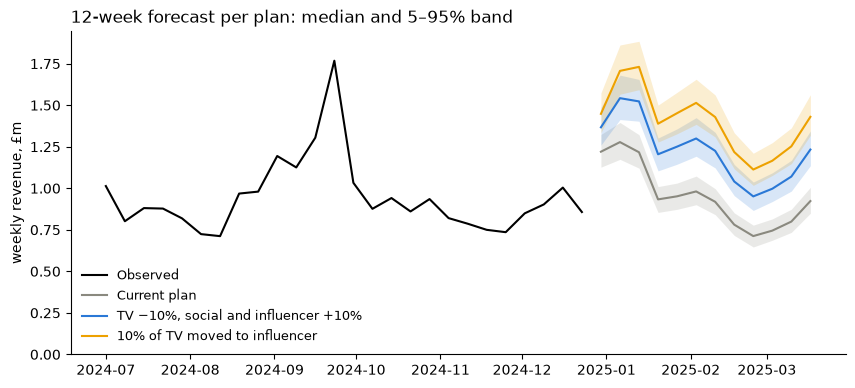

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
hist = data.tail(26)
ax.plot(hist["week_beg"], hist["revenue"] / 1e6, color="black", label="Observed")
for (name, fc), colour in zip(fcs.items(), ["#8a897f", "#2a78d6", "#eda100"]):
    w = fc.weekly
    ax.fill_between(w["week_beg"], w["revenue_p5"] / 1e6, w["revenue_p95"] / 1e6, color=colour, alpha=0.18, linewidth=0)
    ax.plot(w["week_beg"], w["revenue_p50"] / 1e6, color=colour, label=name)
ax.set_ylim(0, None)
ax.set_ylabel("weekly revenue, £m")
ax.set_title("12-week forecast per plan: median and 5–95% band", loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

How good are these forecasts? A back-test: four 12-week forecasts in 2024, each from a model fitted only on the weeks before, given the inputs that actually followed.

In [10]:
bt = backtest()
summary = bt.groupby("origin").agg(error_pct=("abs_pct_error", "mean"), weeks_inside_band=("inside_band", "sum"))
display(summary)
print(f"All 48 weeks: median-forecast error {bt['abs_pct_error'].mean():.1f}%, {bt['inside_band'].mean():.0%} inside the 5–95% band")

,error_pct,weeks_inside_band
origin,,
2024-01-01,3.36,12
2024-04-01,3.90,11
2024-07-01,6.38,9
2024-09-30,2.26,12


All 48 weeks: median-forecast error 4.0%, 92% inside the 5–95% band


## 8. Conclusion

- **Direction:** shift budget from TV to influencers, Instagram and TikTok. Every model version and every scenario agrees on the ranking.
- **First step:** TV −10% within its flights, the three social channels +10% each, same total budget, run as a measured test (one quarter, or some regions).
- **TV and in-store:** TV does not earn its 39% share. POS spend earns its keep but ranks fourth. Price promotions add volume and cost revenue: fewer or shallower promotions is the first in-store lever to test.
- **What we do not claim:** the size of the gain. Social and influencer effects are far above published benchmarks and were only observed in a narrow band of sustained spend. The model's revenue gains are an upper bound until a test confirms them.
- **Limits:** revenue not profit; observational data; intervals cover coefficient uncertainty only. Next: the controlled test, then a Bayesian model with priors from it.